<a href="https://colab.research.google.com/github/JayCarr9305/Machine-Learning/blob/main/carr_662094235.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Carr-662094235

Problem 1

Saving wafer_inspection.png to wafer_inspection.png
Saving nitriding_figure.png to nitriding_figure.png
Image shape: (2400, 2400, 3)


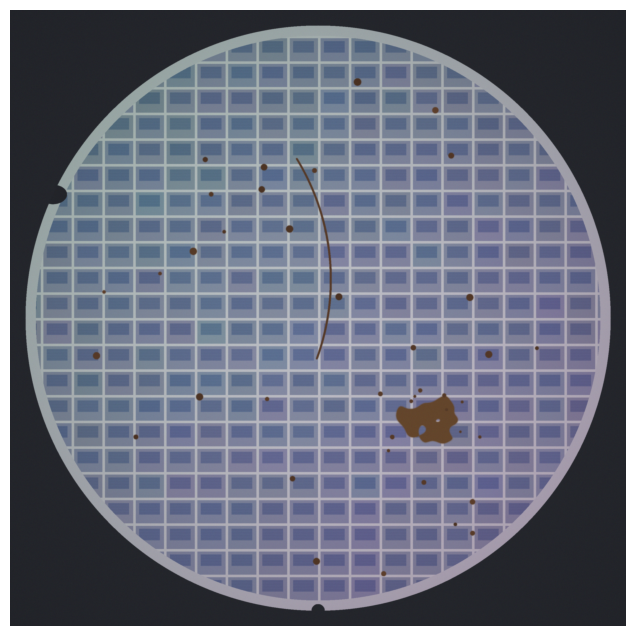

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from google.colab import files

files.upload()  # select wafer_inspection.png

img = plt.imread('wafer_inspection.png')[:, :, :3]  # keep R, G, B
print('Image shape:', img.shape)

plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.axis('off')
plt.show()

1.1: The image shape is (2400, 2400, 3): 2400 × 2400 pixels with 3 colors (RGB)

(5760000, 3)
2 114430.2421875
3 36351.875
4 15210.6181640625
5 12097.0380859375
6 9127.2548828125
7 7333.474609375
8 6488.31201171875


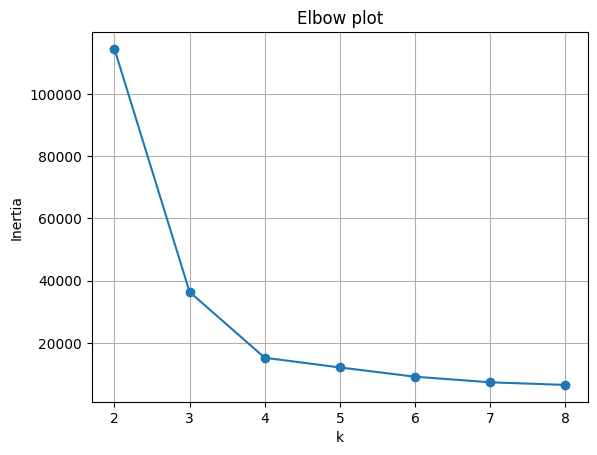

In [ ]:
X = img.reshape(-1, 3)  # each pixel = one sample (R, G, B)
print(X.shape)

inertias = []
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=0)
    kmeans.fit(X)
    inertias.append(kmeans.inertia_)
    print(k, kmeans.inertia_)

plt.plot(range(2, 9), inertias, marker='o')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow plot')
plt.grid(True)
plt.show()

1.2: Based on the plot, four clusters should accurately classify the data. Increasing k further sees minimal decreases in inertia.

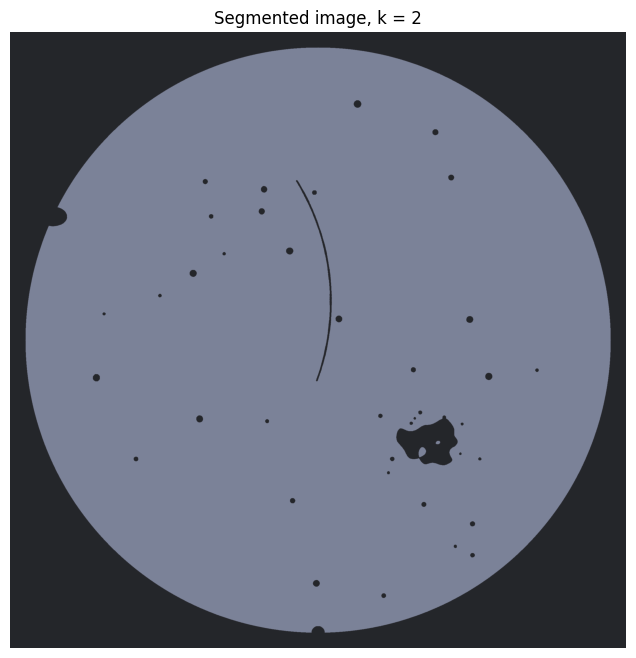

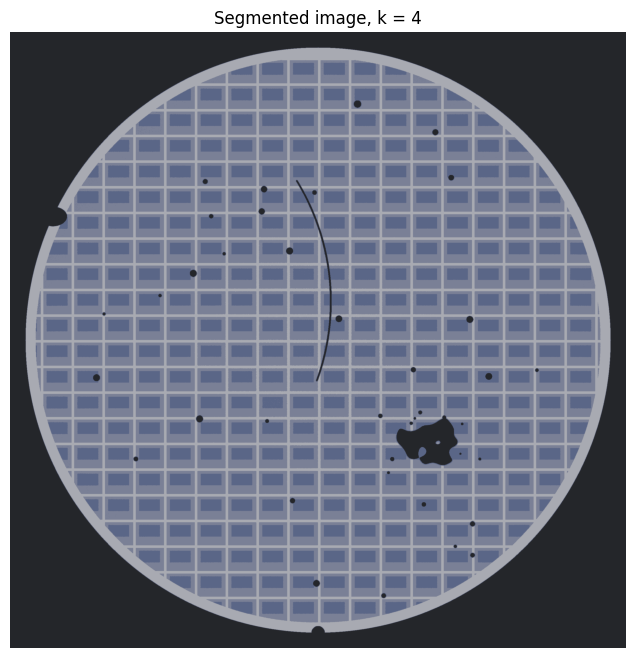

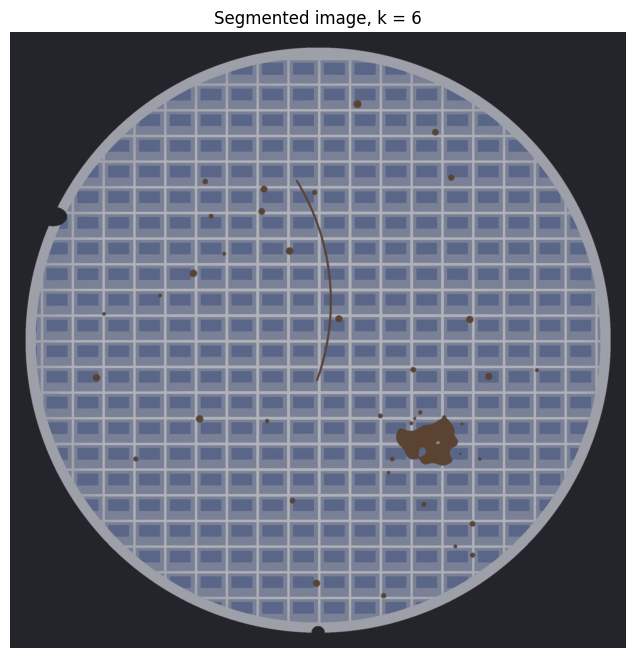

In [ ]:
for k in [2, 4, 6]:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=0)
    labels = kmeans.fit_predict(X)
    segmented = kmeans.cluster_centers_[labels].reshape(img.shape)

    plt.figure(figsize=(8, 8))
    plt.imshow(segmented)
    plt.title(f'Segmented image, k = {k}')
    plt.axis('off')
    plt.show()

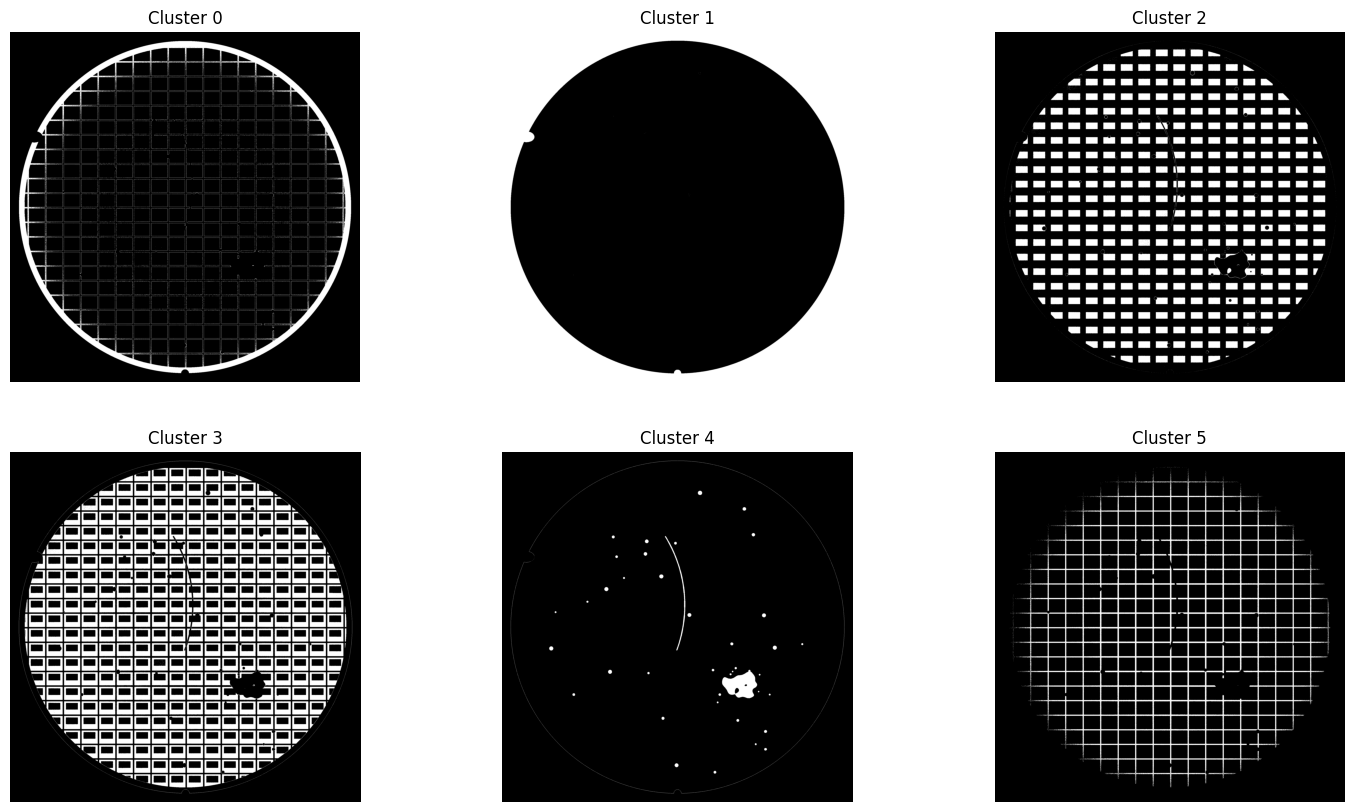

In [ ]:
kmeans6 = KMeans(n_clusters=6, n_init=10, random_state=0)
labels6 = kmeans6.fit_predict(X)

plt.figure(figsize=(18, 10))
for j in range(6):
    plt.subplot(2, 3, j + 1)
    plt.imshow((labels6 == j).reshape(img.shape[:2]), cmap='gray')
    plt.title(f'Cluster {j}')
    plt.axis('off')
plt.show()

In [ ]:
defect = 4

rgb = (kmeans6.cluster_centers_[defect] * 255).round().astype(int)
pixels = np.sum(labels6 == defect)

print('Defect cluster:', defect)
print('Centre RGB:', rgb)
print('Number of pixels:', pixels)

Defect cluster: 4
Centre RGB: [91 67 49]
Number of pixels: 53507


1.3: With k = 6, the defects fall into cluster 4 with a brown center color (RGB = [91 67 49]) containing 53507 pixels.

Based on the plots, a higher number of clusters is required to seperate the defects out because it is similar to the background color and gets grouped together with the background until the are 6 clusters. More clusters are needed to make increasingly specific groupings in the image.

Problem 2

Saving nitriding_data.csv to nitriding_data.csv
furnace
0    30
1    30
Name: count, dtype: int64


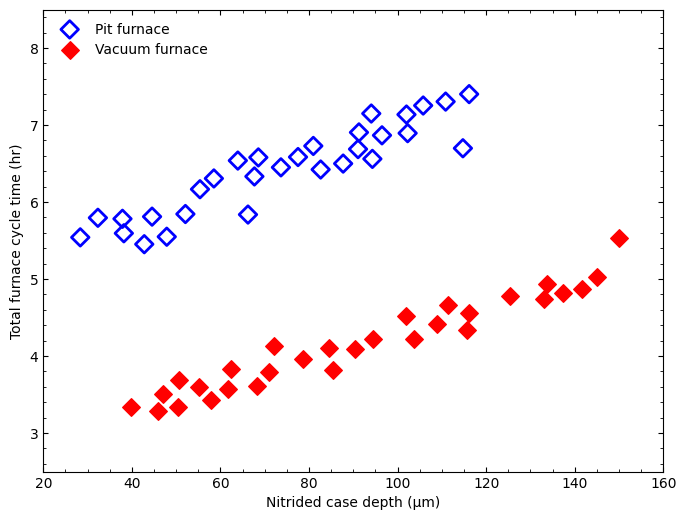

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

files.upload()  # select nitriding_data.csv

df = pd.read_csv('nitriding_data.csv')
print(df['furnace'].value_counts().sort_index())

pit = df[df['furnace'] == 0]
vac = df[df['furnace'] == 1]

plt.figure(figsize=(8, 6))
plt.scatter(pit['case_depth_um'], pit['cycle_time_hr'], marker='D', s=80,
            facecolors='none', edgecolors='blue', linewidths=2, label='Pit furnace')
plt.scatter(vac['case_depth_um'], vac['cycle_time_hr'], marker='D', s=80,
            color='red', label='Vacuum furnace')
plt.xlim(20, 160)
plt.ylim(2.5, 8.5)
plt.xlabel('Nitrided case depth (µm)')
plt.ylabel('Total furnace cycle time (hr)')
plt.minorticks_on()
plt.tick_params(which='both', direction='in', top=True, right=True)
plt.legend(loc='upper left', frameon=False)
plt.show()

R^2 on test set: 0.9455093807870149


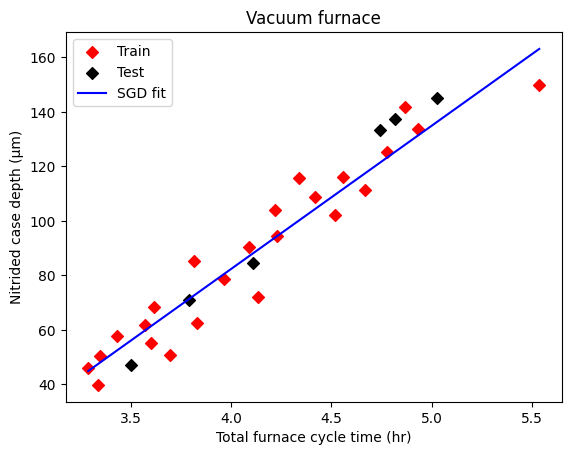

Cycle time 3.500 hr -> predicted case depth = 56.0 µm
Cycle time 4.250 hr -> predicted case depth = 95.5 µm
Cycle time 4.833 hr -> predicted case depth = 126.2 µm


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import r2_score

vac = df[df['furnace'] == 1]
X = vac[['cycle_time_hr']].values
y = vac['case_depth_um'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

sgd = SGDRegressor(loss='squared_error', penalty='l2', alpha=0.001, max_iter=1000,
                   tol=1e-3, learning_rate='constant', eta0=0.01, random_state=0)
sgd.fit(X_train_s, y_train)

print('R^2 on test set:', r2_score(y_test, sgd.predict(X_test_s)))

# Plot data and fitted line
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line = sgd.predict(scaler.transform(x_line))

plt.scatter(X_train, y_train, color='red', marker='D', label='Train')
plt.scatter(X_test, y_test, color='black', marker='D', label='Test')
plt.plot(x_line, y_line, 'b-', label='SGD fit')
plt.xlabel('Total furnace cycle time (hr)')
plt.ylabel('Nitrided case depth (µm)')
plt.title('Vacuum furnace')
plt.legend()
plt.show()

# Predictions: 3 h 30 min, 4 h 15 min, 4 h 50 min
new_times = np.array([[3.5], [4.25], [4 + 50/60]])
preds = sgd.predict(scaler.transform(new_times))
for t, p in zip(new_times.ravel(), preds):
    print(f'Cycle time {t:.3f} hr -> predicted case depth = {p:.1f} µm')

Accuracy:  1.0
Precision: 1.0
Recall:    1.0


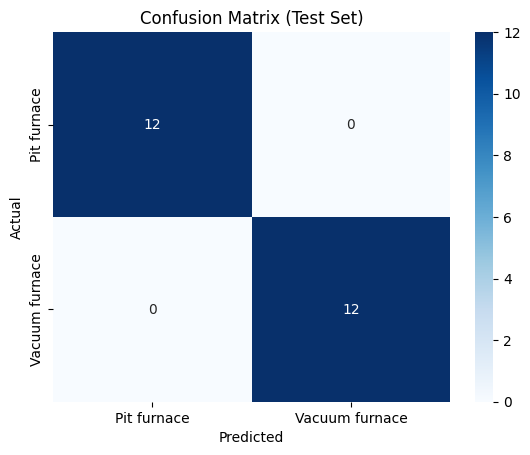

In [ ]:
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

X = df[['case_depth_um', 'cycle_time_hr']].values
y = df['furnace'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0, stratify=y)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

log_reg = LogisticRegression()
log_reg.fit(X_train_s, y_train)
y_pred = log_reg.predict(X_test_s)

print('Accuracy: ', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall:   ', recall_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
labels = ['Pit furnace', 'Vacuum furnace']
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Test Set)')
plt.show()

The test accuracy is 100%, this makes sense since the data is clearly seperate and a linear model can easily seperate the two.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


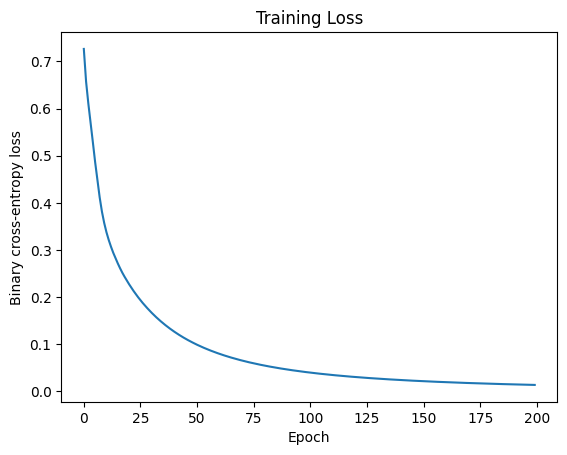

Test accuracy: 1.0


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras import optimizers

tf.keras.utils.set_random_seed(0)

model = Sequential()
model.add(Dense(8, activation='relu', input_shape=[2]))
model.add(Dense(4, activation='relu'))
model.add(Dense(1, activation='sigmoid'))
model.compile(optimizer=optimizers.Adam(learning_rate=0.01),
              loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train_s, y_train, epochs=200, batch_size=8, verbose=0)

plt.plot(history.history['loss'])
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy loss')
plt.show()

print('Test accuracy:', model.evaluate(X_test_s, y_test, verbose=0)[1])

In [ ]:
gears = np.array([[110, 4.6],   # gear A
                  [40, 4.6]])   # gear B
gears_s = scaler.transform(gears)

p_lr = log_reg.predict_proba(gears_s)[:, 1]
p_nn = model.predict(gears_s).ravel()

names = ['Pit furnace', 'Vacuum furnace']
for g, a, b in zip(['A', 'B'], p_lr, p_nn):
    print(f'Gear {g}: Logistic regression -> {names[int(a > 0.5)]}, P(vacuum) = {a:.3f} | '
          f'Neural network -> {names[int(b > 0.5)]}, P(vacuum) = {b:.3f}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
Gear A: Logistic regression -> Vacuum furnace, P(vacuum) = 0.889 | Neural network -> Vacuum furnace, P(vacuum) = 1.000
Gear B: Logistic regression -> Vacuum furnace, P(vacuum) = 0.555 | Neural network -> Vacuum furnace, P(vacuum) = 0.916


2.4) c. The models disagree the most in their probabilities with Gear B (Logistic Regression = .555 and NN = .916). The logistic regression uses a linear model to predict the case depth. For a logged cycle time of 4.6 hours, the logistic regression model predicts a case depth of ~110 micrometers. To achieve a depth of 40 micrometers, pit furnaces need 5.6 hours and vacuum furnaces need 3.3. The 4.6 hours falls right between the two groups, where there is no training data. I would trust the logistic regression answer of .555 because it shows that it doesn't really know what furnace it is. The neural network has false confidence in a region it is not trained in.